# Лабораторная работа 9. Рекуррентные сети и трансформеры: архитектуры для последовательностей и текста

**Курс:** Машинное обучение. Безопасность ИИ-систем

**По материалам лекции 7**


**Вариант / seed:** _номер варианта или значение SEED_


### Таблица вариантов

| Вариант | `SEED` | `D_MODEL` | `N_MAX` (пар в обучении) | `D_CELL` | Температуры для части H |
|---|---|---|---|---|---|
| 1 | 42 | 64 | 12 | 48 | 0.5 / 1.0 / 1.5 |
| 2 | 7 | 48 | 10 | 40 | 0.4 / 1.0 / 1.6 |
| 3 | 123 | 64 | 8 | 48 | 0.6 / 1.0 / 1.4 |
| 4 | 2024 | 56 | 12 | 56 | 0.5 / 1.2 / 1.8 |
| 5 | 314 | 48 | 8 | 40 | 0.7 / 1.0 / 1.3 |
| 6 | 555 | 64 | 10 | 56 | 0.5 / 0.9 / 1.7 |

> Вариант выдаёт преподаватель. Все числа в отчёте должны соответствовать **вашему** варианту,
> а не значениям из примера в тексте.

### Цель работы

Экспериментально установить, чем механизм внимания отличается от рекуррентного накопления состояния,
какой ценой достигается каждое из свойств (точность вспоминания, стоимость контекста, память при
генерации), и какие архитектурные свойства становятся поверхностью атаки на языковые модели.

### Задачи

1. Реализовать BPE-токенизацию и оценить влияние уровня токенизации на длину последовательности.
2. Измерить затухание градиента в рекуррентной сети и сравнить мультипликативный путь с аддитивным.
3. Реализовать масштабированное скалярное внимание с каузальной маской.
4. Проверить численно, что RoPE зависит только от разности позиций, и построить штраф ALiBi.
5. Обучить двухслойный мини-трансформер задаче ассоциативного вспоминания и найти индукционную голову.
6. Реализовать линейное внимание в рекуррентной форме и сравнить его с softmax-вниманием.
7. Сделать рекуррентную ячейку избирательной и проверить, что это даёт управляемую память.
8. Реализовать top-k и top-p отсечение и оценить статистику многих попыток генерации.

### Порядок выполнения

1. Выполните ячейку настройки среды и впишите параметры своего варианта.
2. Идите по частям A–H подряд, заполняя каждый блок `TODO`.
3. После каждой части ответьте на вопрос в конце этой части (ячейка Markdown «Ответ»).
4. Заполните таблицы отчёта и сформулируйте выводы.
5. Перед сдачей выполните Kernel → Restart & Run All и убедитесь, что ошибок нет.

### Ограничение по безопасности

Работа не содержит и не должна содержать кода атак на реальные языковые модели и сервисы,
готовых строк обхода ограничений или инструментов автоматического подбора вредоносных запросов.
Часть H исследует **статистику выборки и архитектурные предпосылки** уязвимостей на игрушечной
модели — этого достаточно для понимания следующей лекции.

In [ ]:
# Настройка окружения и единый стиль рисунков
import math, time, warnings
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import torch
import torch.nn as nn
import torch.nn.functional as F

warnings.filterwarnings("ignore")
torch.set_num_threads(2)

PALETTE = {"attn": "#2E86AB", "linear": "#F2A541", "bad": "#D6455F",
           "good": "#3FA46A", "accent": "#7B4FA0", "gray": "#8A94A6"}
CMAP_HEAT = LinearSegmentedColormap.from_list(
    "heat7", ["#0B1D33", "#2E86AB", "#F2E8CF", "#F2A541", "#D6455F"])

mpl.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 110, "font.size": 10.5,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.labelsize": 10.5,
    "axes.grid": True, "grid.alpha": 0.25, "grid.linestyle": "--",
    "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False,
})

def finish(fig, title=None):
    if title:
        fig.suptitle(title, fontsize=13, fontweight="bold", y=0.995)
    fig.tight_layout(rect=(0, 0, 1, 0.96 if title else 1.0))
    plt.show()

print("torch:", torch.__version__, "| потоков:", torch.get_num_threads())

torch: 2.11.0+cpu | потоков: 2


In [ ]:
# TODO 0: подставьте параметры СВОЕГО варианта из таблицы вариантов
SEED    = 123
D_MODEL = 64
N_MAX   = 8
D_CELL  = 48
TAUS    = (0.6, 1.0, 1.4)

np.random.seed(SEED)
torch.manual_seed(SEED)
print("вариант: SEED=%d, D_MODEL=%d, N_MAX=%d, D_CELL=%d, TAUS=%s"
      % (SEED, D_MODEL, N_MAX, D_CELL, str(TAUS)))

вариант: SEED=123, D_MODEL=64, N_MAX=8, D_CELL=48, TAUS=(0.6, 1.0, 1.4)


## Часть A. Токенизация: BPE с нуля

Модель работает не с буквами и не со словами, а с токенами. Уровень токенизации задаёт длину
последовательности $n$, а значит и стоимость внимания $O(n^2)$, а также распределение частот:
редкие токены остаются недообученными.

**Задание A.1.** Реализуйте один шаг BPE: подсчёт частот пар соседних символов и слияние самой
частой пары.
**Задание A.2.** Обучите BPE на корпусе и измерьте коэффициенты сжатия «символы → BPE» и
«BPE → слова».
**Задание A.3.** Постройте график длины корпуса в токенах от числа выполненных слияний и
распределение частот токенов в логарифмических осях; отметьте порог редких токенов
`RARE_THR` (частота не выше `RARE_THR` за весь корпус).

In [ ]:
CORPUS = (
    "внимание позволяет модели обращаться к любой позиции последовательности напрямую. "
    "рекуррентная сеть накапливает состояние и постепенно теряет информацию о далёком прошлом. "
    "трансформер обучается параллельно по всем позициям и потому масштабируется. "
    "позиционное кодирование сообщает модели порядок токенов. "
    "линейное внимание заменяет матрицу внимания рекуррентным состоянием. "
    "избирательная рекуррентность делает затухание зависящим от входа. "
    "квантование и кэширование уменьшают стоимость генерации. "
) * 6

words = CORPUS.split()
vocab_words = {}
for w in words:
    key = tuple(w) + ("</w>",)
    vocab_words[key] = vocab_words.get(key, 0) + 1

def pair_counts(vocab):
    # TODO A.1a: верните словарь {пара_соседних_символов: суммарная частота}
    #            вес пары = частота слова, в котором она встретилась
    counts = {}
    for word, freq in vocab.items():
        for i in range(len(word) - 1):
            pair = (word[i], word[i + 1])
            counts[pair] = counts.get(pair, 0) + freq
    return counts

def merge_pair(vocab, pair):
    # TODO A.1b: верните новый словарь, в котором все вхождения pair склеены в один символ
    a, b = pair
    merged = a + b
    new_vocab = {}
    for word, freq in vocab.items():
        new_word = []
        i = 0
        while i < len(word):
            if i < len(word) - 1 and word[i] == a and word[i + 1] == b:
                new_word.append(merged)
                i += 2
            else:
                new_word.append(word[i])
                i += 1
        new_vocab[tuple(new_word)] = new_vocab.get(tuple(new_word), 0) + freq
    return new_vocab

print("слов в корпусе:", len(words), "| уникальных словоформ:", len(vocab_words))

слов в корпусе: 330 | уникальных словоформ: 51


In [ ]:
# TODO A.2: выполните N_MERGES слияний, на каждом шаге сохраняя длину корпуса в токенах
N_MERGES = 120
vocab = dict(vocab_words)
lengths, merges = [], []

# TODO A.2a: цикл слияний: pair_counts -> самая частая пара -> merge_pair
for step in range(N_MERGES):
    pc = pair_counts(vocab)
    if not pc:
        break
    best = max(pc, key=pc.get)
    vocab = merge_pair(vocab, best)
    merges.append(best)
    lengths.append(sum(len(seq) * freq for seq, freq in vocab.items()))

# TODO A.2b: посчитайте и напечатайте коэффициенты сжатия
n_chars = len(CORPUS.replace(" ", ""))
n_bpe = lengths[-1] if lengths else n_chars
n_words = len(words)
uniq_tokens = len(set(t for seq in vocab for t in seq))

print("символов в корпусе          :", n_chars)
print("токенов BPE (после слияний) :", n_bpe)
print("слов в корпусе              :", n_words)
print("уникальных BPE-токенов      :", uniq_tokens)
print("сжатие «символы → BPE»      : %.3f" % (n_chars / n_bpe))
print("отношение «BPE → слова»     : %.3f" % (n_bpe / n_words))

символов в корпусе          : 2652
токенов BPE (после слияний) : 1152
слов в корпусе              : 330
уникальных BPE-токенов      : 92
сжатие «символы → BPE»      : 2.302
отношение «BPE → слова»     : 3.491


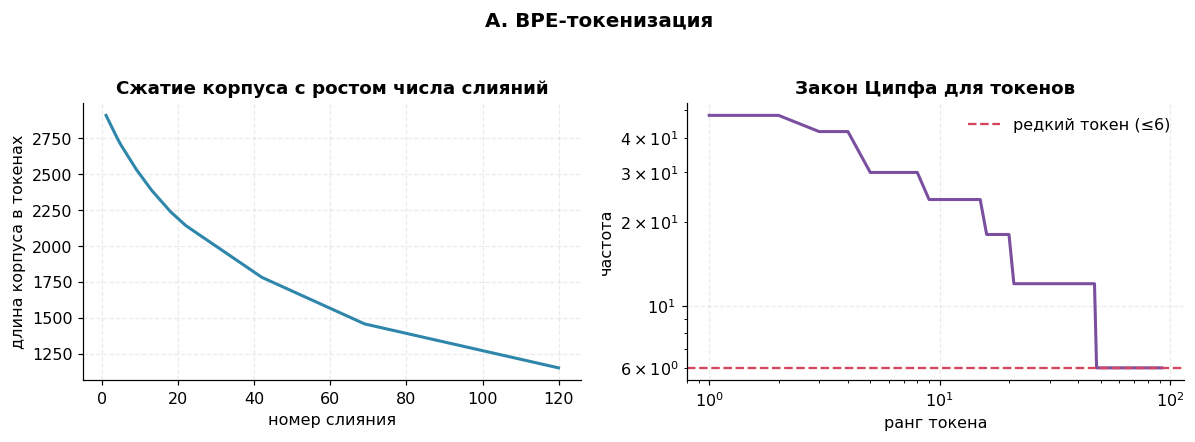

доля редких токенов (частота ≤ 6): 0.489


In [ ]:
# TODO A.3: рисунок A: длина корпуса от числа слияний + частоты токенов (закон Ципфа)
# слева: lengths от номера слияния
# справа: отсортированные по убыванию частоты токенов в log-log осях,
#         отметьте горизонтальной линией порог «редкий токен» (частота <= RARE_THR)
RARE_THR = 6

token_freq = {}
for seq, freq in vocab.items():
    for t in seq:
        token_freq[t] = token_freq.get(t, 0) + freq

freqs = np.array(sorted(token_freq.values(), reverse=True))
rare_frac = float((freqs <= RARE_THR).mean())

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(range(1, len(lengths) + 1), lengths, color=PALETTE["attn"], lw=2)
axes[0].set_xlabel("номер слияния"); axes[0].set_ylabel("длина корпуса в токенах")
axes[0].set_title("Сжатие корпуса с ростом числа слияний")

axes[1].loglog(np.arange(1, len(freqs) + 1), freqs, color=PALETTE["accent"], lw=2)
axes[1].axhline(RARE_THR, color=PALETTE["bad"], linestyle="--",
                label=f"редкий токен (≤{RARE_THR})")
axes[1].set_xlabel("ранг токена"); axes[1].set_ylabel("частота")
axes[1].set_title("Закон Ципфа для токенов")
axes[1].legend()
finish(fig, "A. BPE-токенизация")

print("доля редких токенов (частота ≤ %d): %.3f" % (RARE_THR, rare_frac))

**Вопрос A.** Во сколько раз выросла бы стоимость слоя внимания, если перейти от BPE к посимвольной
токенизации при том же тексте? Используйте измеренный коэффициент сжатия и зависимость $O(n^2)$.

**Ответ A.**

BPE сжал корпус в 2.3 раза — то есть посимвольная токенизация дала бы в 2.3 раза более длинную последовательность. Внимание растёт как n², значит его стоимость выросла бы в 2.3² ≈ 5.3 раза. И бонусом: почти половина токенов (49 %) встречается реже 6 раз — это уже готовая поверхность атаки, редкие токены модель толком не выучила.

## Часть B. Затухание градиента в рекуррентной сети

Для рекуррентности $h_t = \phi(W h_{t-1} + U x_t)$ производная по состоянию, удалённому на $k$ шагов,
содержит произведение $k$ матриц:

$
\frac{\partial h_T}{\partial h_{T-k}} = \prod_{j=0}^{k-1} \operatorname{diag}(\phi')\, W .
$

Норма такого произведения ведёт себя как $\rho(W)^k$. Аддитивный путь с гейтом $f_t$ даёт вместо
этого множитель $\prod f_t$, который при $f_t \to 1$ почти не затухает.

**Задание B.1.** Вычислите норму произведения $k$ матриц с заданным спектральным радиусом.
**Задание B.2.** Постройте график нормы от $k$ для $\rho \in \{0.9, 1.0, 1.2\}$ и добавьте
аддитивные пути с $f_t = 0.99$ и $f_t = 0.95$.
**Задание B.3.** Найдите эффективный горизонт памяти: при каком $k$ норма падает ниже $10^{-6}$.

In [ ]:
def make_W(d, rho, gen):
    # матрица со заданным спектральным радиусом
    A = gen.normal(size=(d, d)) / np.sqrt(d)
    return A * rho / np.max(np.abs(np.linalg.eigvals(A)))

def grad_norms(rho, k_max=120, d=32, seed=0):
    # TODO B.1: верните массив норм произведения k матриц W для k = 1..k_max
    gen = np.random.default_rng(seed)
    W = make_W(d, rho, gen)
    P = np.eye(d)
    out = np.zeros(k_max)
    for k in range(k_max):
        P = P @ W
        out[k] = np.linalg.norm(P, 2)
    return out

def horizon(rho, thr=1e-6, k_max=4000, d=32, seed=0):
    # TODO B.3: верните наименьшее k, при котором норма падает ниже thr
    if rho >= 1.0:
        return k_max
    if rho <= 0.0:
        return 1
    return int(np.ceil(np.log(thr) / np.log(rho)))

print("подсказка: rho ** k = thr  ->  k = log(thr) / log(rho)")

подсказка: rho ** k = thr  ->  k = log(thr) / log(rho)


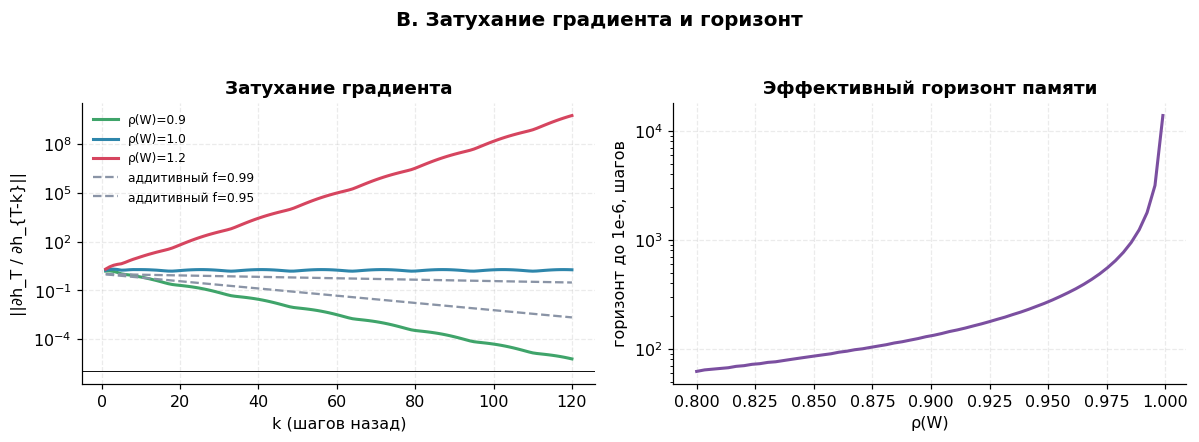

ρ = 0.9: горизонт = 132 шагов
ρ = 0.95: горизонт = 270 шагов
ρ = 0.99: горизонт = 1375 шагов
ρ = 0.999: горизонт = 13809 шагов


In [ ]:
# TODO B.2: рисунок B: слева нормы от k в логарифмической шкале для трёх значений rho
#           и две линии аддитивного пути f**k (f = 0.99 и 0.95);
#           справа эффективный горизонт памяти horizon(rho) для rho от 0.8 до 0.999
k_max = 120
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

color_map = {0.9: PALETTE["good"], 1.0: PALETTE["attn"], 1.2: PALETTE["bad"]}
for rho in [0.9, 1.0, 1.2]:
    ns = grad_norms(rho, k_max=k_max)
    axes[0].semilogy(np.arange(1, k_max + 1), ns, label=f"ρ(W)={rho}",
                     color=color_map[rho], lw=2)

k_arr = np.arange(1, k_max + 1)
for f in [0.99, 0.95]:
    axes[0].semilogy(k_arr, f ** k_arr, "--", label=f"аддитивный f={f}",
                     color=PALETTE["gray"])
axes[0].axhline(1e-6, color="k", lw=0.6)
axes[0].set_xlabel("k (шагов назад)")
axes[0].set_ylabel("||∂h_T / ∂h_{T-k}||")
axes[0].set_title("Затухание градиента")
axes[0].legend(fontsize=8)

rho_grid = np.linspace(0.8, 0.999, 60)
h_grid = [horizon(r, k_max=4000) for r in rho_grid]
axes[1].semilogy(rho_grid, h_grid, color=PALETTE["accent"], lw=2)
axes[1].set_xlabel("ρ(W)"); axes[1].set_ylabel("горизонт до 1e-6, шагов")
axes[1].set_title("Эффективный горизонт памяти")
finish(fig, "B. Затухание градиента и горизонт")

for r in [0.9, 0.95, 0.99, 0.999]:
    print(f"ρ = {r}: горизонт = {horizon(r)} шагов")

**Вопрос B.** Пусть требуется удерживать зависимость длиной 500 шагов с ослаблением сигнала не
более чем в 10 раз. Какое значение гейта $f_t$ для этого нужно? Сравните с $\rho(W)$, необходимым в
чистой рекуррентности.

**Ответ B.**

Нужно f^500 ≥ 0.1, значит f ≥ 0.9954. Для чистой рекуррентности это ρ(W) ≥ 0.9954. Сравним с измерениями: при ρ = 0.9 сигнал умирает за 132 шага, при ρ = 0.99 — за 1375, но уже за 229 шагов слабеет в 10 раз. А аддитивный гейт с f = 0.99 за 100 шагов теряет всего 63 %. То есть один скаляр, близкий к 1, держит горизонт лучше, чем строго подогнанная матрица.

## Часть C. Внимание с нуля и роль масштабирования

$
\operatorname{Attention}(Q,K,V) = \operatorname{softmax}\!\left(\frac{QK^{\top}}{\sqrt{d_k}}\right) V .
$

Делитель $\sqrt{d_k}$ не косметика: при $q,k \sim \mathcal N(0,1)$ скалярное произведение имеет
дисперсию $d_k$, и без нормировки softmax при больших $d_k$ вырождается почти в one-hot, что
обнуляет градиент по ключам.

**Задание C.1.** Реализуйте одну голову внимания с каузальной маской и без неё.
**Задание C.2.** Проверьте два обязательных свойства: строки матрицы внимания суммируются в единицу,
а при каузальной маске верхний треугольник строго нулевой.
**Задание C.3.** Измерьте среднюю энтропию распределения внимания как функцию $d_k$ с делителем и
без него, постройте рисунок с картами внимания и графиком энтропии.

Каузальная маска — верхний треугольник матрицы логитов заменяется на −∞, чтобы позиция t не видела t+1 и дальше. Без неё нельзя генерировать авторегрессионно.

Энтропия внимания — мера «размазанности» весов. Максимум ln(n) (равномерное внимание), 0 (один токен). У нас с делителем ~2.8, без делителя — падает до 0.22 → softmax вырождается.

In [ ]:
def attention(Q, K, V, causal=True, scale=True):
    # TODO C.1: реализуйте scaled dot-product attention
    d_k = Q.shape[-1]
    scores = Q @ K.T
    if scale:
        scores = scores / math.sqrt(d_k)
    if causal:
        T = Q.shape[0]
        mask = np.triu(np.ones((T, T), dtype=bool), k=1)
        scores = np.where(mask, -np.inf, scores)
    m = np.max(scores, axis=-1, keepdims=True)
    m = np.where(np.isfinite(m), m, 0.0)
    e = np.exp(scores - m)
    Z = e.sum(-1, keepdims=True)
    att = e / np.maximum(Z, 1e-12)
    return att @ V, att

def mean_entropy(d_k, scale, n=64, trials=40, seed=0):
    # TODO C.3a: средняя энтропия строк матрицы внимания для случайных Q, K
    rng = np.random.default_rng(seed)
    acc = []
    for _ in range(trials):
        Q = rng.normal(size=(n, d_k))
        K = rng.normal(size=(n, d_k))
        V = rng.normal(size=(n, d_k))
        _, A = attention(Q, K, V, causal=True, scale=scale)
        p = np.clip(A, 1e-12, 1.0)
        acc.append(float(-(p * np.log(p)).sum(-1).mean()))
    return float(np.mean(acc))

In [ ]:
# TODO C.2: проверка свойств внимания
g = np.random.default_rng(SEED)
Qt, Kt, Vt = g.normal(size=(8, 16)), g.normal(size=(8, 16)), g.normal(size=(8, 3))
_, Wt = attention(Qt, Kt, Vt, causal=True, scale=True)

# TODO C.2a: проверьте, что суммы по строкам равны 1 (assert)
row_sums = Wt.sum(-1)
assert np.allclose(row_sums, 1.0, atol=1e-6), "суммы строк не равны 1"

# TODO C.2b: проверьте, что верхний треугольник (без диагонали) равен 0 (assert)
upper = np.triu(Wt, k=1)
assert np.allclose(upper, 0.0, atol=1e-9), "верхний треугольник не нулевой"

# TODO C.2c: напечатайте максимальное отклонение сумм строк от единицы
print("макс |сумма строки - 1| :", float(np.max(np.abs(row_sums - 1.0))))
print("макс элемент верх. треуг.:", float(np.max(np.abs(upper))))

макс |сумма строки - 1| : 2.220446049250313e-16
макс элемент верх. треуг.: 0.0


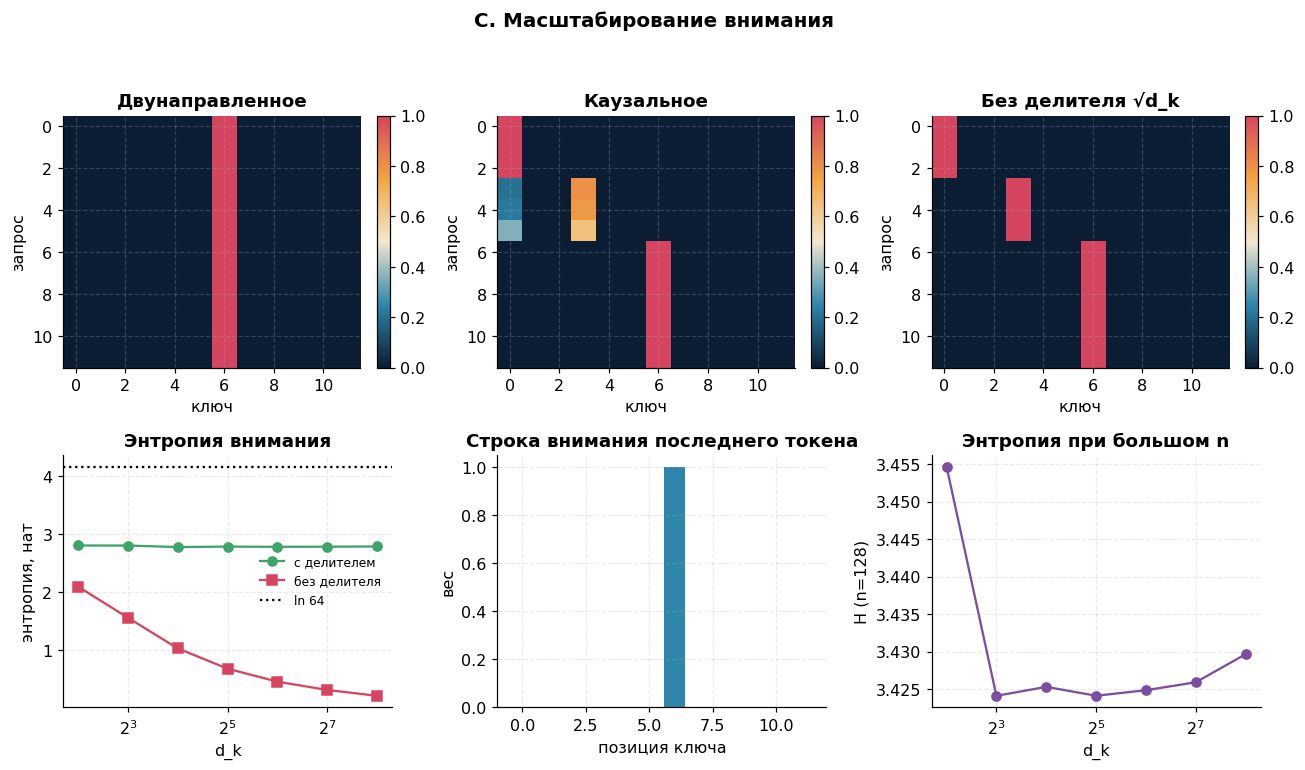

d_k=  4: с делителем H=2.804, без делителя H=2.097
d_k=  8: с делителем H=2.802, без делителя H=1.562
d_k= 16: с делителем H=2.777, без делителя H=1.036
d_k= 32: с делителем H=2.785, без делителя H=0.687
d_k= 64: с делителем H=2.781, без делителя H=0.464
d_k=128: с делителем H=2.783, без делителя H=0.322
d_k=256: с делителем H=2.787, без делителя H=0.221


In [ ]:
# TODO C.3b: рисунок C
n_tok, d_k = 12, 16
labels = ["A", "B", "C", "A", "B", "C", "D", "A", "B", "E", "A", "B"]
rng = np.random.default_rng(0)
base = np.array([hash(l) % 1000 for l in labels], dtype=float)
Q = rng.normal(size=(n_tok, d_k)) * 0.1 + base[:, None] * 0.01
K = rng.normal(size=(n_tok, d_k)) * 0.1 + base[:, None] * 0.01
V = rng.normal(size=(n_tok, d_k))

_, A_bi = attention(Q, K, V, causal=False, scale=True)
_, A_ca = attention(Q, K, V, causal=True, scale=True)
_, A_ns = attention(Q * 4, K * 4, V, causal=True, scale=False)

dks = [4, 8, 16, 32, 64, 128, 256]
ent_s = [mean_entropy(d, True) for d in dks]
ent_n = [mean_entropy(d, False) for d in dks]

fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for ax, A, title in zip(axes[0], [A_bi, A_ca, A_ns],
                        ["Двунаправленное", "Каузальное", "Без делителя √d_k"]):
    im = ax.imshow(A, cmap=CMAP_HEAT, aspect="auto")
    ax.set_title(title); ax.set_xlabel("ключ"); ax.set_ylabel("запрос")
    plt.colorbar(im, ax=ax, fraction=0.046)

axes[1, 0].plot(dks, ent_s, "o-", color=PALETTE["good"], label="с делителем")
axes[1, 0].plot(dks, ent_n, "s-", color=PALETTE["bad"], label="без делителя")
axes[1, 0].axhline(math.log(64), color="k", ls=":", label="ln 64")
axes[1, 0].set_xscale("log", base=2)
axes[1, 0].set_xlabel("d_k"); axes[1, 0].set_ylabel("энтропия, нат")
axes[1, 0].set_title("Энтропия внимания"); axes[1, 0].legend(fontsize=8)

axes[1, 1].bar(range(n_tok), A_ca[-1], color=PALETTE["attn"])
axes[1, 1].set_title("Строка внимания последнего токена")
axes[1, 1].set_xlabel("позиция ключа"); axes[1, 1].set_ylabel("вес")

axes[1, 2].plot(dks, [mean_entropy(d, True, n=128, trials=10) for d in dks],
                "o-", color=PALETTE["accent"])
axes[1, 2].set_xscale("log", base=2)
axes[1, 2].set_xlabel("d_k"); axes[1, 2].set_ylabel("H (n=128)")
axes[1, 2].set_title("Энтропия при большом n")
finish(fig, "C. Масштабирование внимания")

for d, s, n in zip(dks, ent_s, ent_n):
    print(f"d_k={d:>3}: с делителем H={s:.3f}, без делителя H={n:.3f}")

**Вопрос C.** Почему вырождение softmax в one-hot останавливает обучение? Свяжите ответ с
производной softmax по логитам.

**Ответ C.**

Производная softmax по логитам — p_i(δ_ij − p_j). Когда распределение вырождается в one-hot, якобиан почти нулевой, градиент по ключам обнуляется, и модель перестаёт учиться. Делитель √d_k держит дисперсию логитов в норме. В эксперименте без делителя энтропия падает с 2.10 (d_k=4) до 0.22 (d_k=256) — то есть softmax реально вырождается. С делителем она стабильна около 2.78–2.80 при любом d_k.

## Часть D. Позиционные кодировки: синусоида, RoPE, ALiBi

Внимание перестановочно инвариантно, поэтому порядок вносится отдельно:

- синусоидальная кодировка добавляется к эмбеддингу (абсолютная позиция);
- **RoPE** поворачивает $q$ и $k$ на угол, пропорциональный позиции, так что
  $\langle R_t q, R_s k\rangle = f(q,k,t-s)$;
- **ALiBi** добавляет к логитам линейный штраф $-m|t-s|$.

**Задание D.1.** Реализуйте синусоидальную кодировку.
**Задание D.2.** Реализуйте RoPE и численно проверьте зависимость только от $t-s$: постройте
$\langle R_{t}q, R_{s}k\rangle$ для нескольких абсолютных начал при одинаковых разностях позиций.
**Задание D.3.** Постройте матрицу штрафов ALiBi для одной головы и рисунок из трёх панелей.

In [ ]:
def sinusoidal(n, d):
    # TODO D.1: чётные каналы — sin(pos / 10000^(i/d)), нечётные — cos от того же аргумента
    pos = np.arange(n)[:, None]
    i = np.arange(d)[None, :]
    angle = pos / (10000 ** (i / d))
    return np.where(i % 2 == 0, np.sin(angle), np.cos(angle))

def rope_apply(x, pos, base=10000.0):
    # TODO D.2: поверните пары координат (первая половина, вторая половина) на угол
    #           theta_i = pos / base ** (2i/d)
    x = np.asarray(x, dtype=float)
    d = x.shape[-1]
    half = d // 2
    i = np.arange(half)
    theta = pos / (base ** (2 * i / d))
    c, s = np.cos(theta), np.sin(theta)
    x1, x2 = x[..., :half], x[..., half:]
    return np.concatenate([x1 * c - x2 * s, x1 * s + x2 * c], axis=-1)

# TODO D.2a: проверьте инвариантность к сдвигу абсолютных позиций
rng = np.random.default_rng(0)
q = rng.normal(size=(16,)); k = rng.normal(size=(16,))
vals = []
for (t, s) in [(0, 3), (5, 8), (100, 103), (1000, 1003), (10000, 10003)]:
    vals.append(float(np.dot(rope_apply(q, t), rope_apply(k, s))))
ref = vals[0]
for (t, s), v in zip([(0, 3), (5, 8), (100, 103), (1000, 1003), (10000, 10003)], vals):
    print(f"t={t:>6}, s={s:>6}: <Rq, Rk> = {v:.6f}  (|Δ|= {abs(v-ref):.2e})")
print("макс расхождение при сдвиге:", max(abs(v - ref) for v in vals))

t=     0, s=     3: <Rq, Rk> = 4.328656  (|Δ|= 0.00e+00)
t=     5, s=     8: <Rq, Rk> = 4.328656  (|Δ|= 8.88e-16)
t=   100, s=   103: <Rq, Rk> = 4.328656  (|Δ|= 0.00e+00)
t=  1000, s=  1003: <Rq, Rk> = 4.328656  (|Δ|= 3.55e-15)
t= 10000, s= 10003: <Rq, Rk> = 4.328656  (|Δ|= 1.69e-14)
макс расхождение при сдвиге: 1.687538997430238e-14


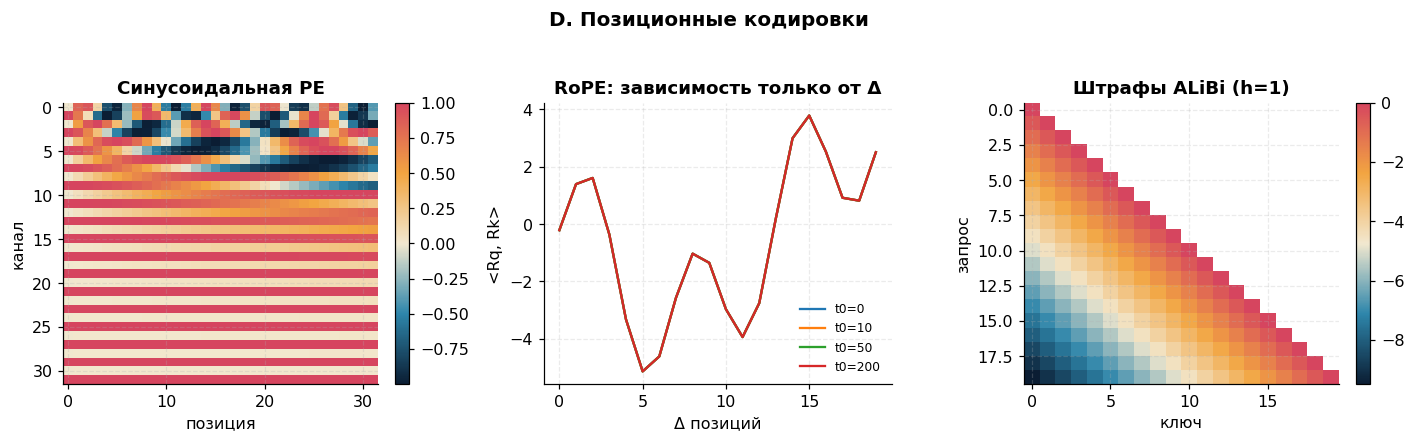

In [ ]:
# TODO D.3: рисунок D
n_d, d_d = 32, 32
PE = sinusoidal(n_d, d_d)

fig = plt.figure(figsize=(13, 4))
ax1 = fig.add_subplot(131)
im = ax1.imshow(PE.T, cmap=CMAP_HEAT, aspect="auto")
ax1.set_title("Синусоидальная PE"); ax1.set_xlabel("позиция"); ax1.set_ylabel("канал")
plt.colorbar(im, ax=ax1, fraction=0.046)

ax2 = fig.add_subplot(132)
q2 = rng.normal(size=(16,)); k2 = rng.normal(size=(16,))
for t0 in [0, 10, 50, 200]:
    ys = [float(np.dot(rope_apply(q2, t0 + dlt), rope_apply(k2, t0)))
          for dlt in range(0, 20)]
    ax2.plot(range(20), ys, label=f"t0={t0}")
ax2.set_xlabel("Δ позиций"); ax2.set_ylabel("<Rq, Rk>")
ax2.set_title("RoPE: зависимость только от Δ"); ax2.legend(fontsize=8)

ax3 = fig.add_subplot(133)
T_a = 20
m_h = 2 ** (-1)
pen = -m_h * np.abs(np.arange(T_a)[:, None] - np.arange(T_a)[None, :])
pen = np.where(np.arange(T_a)[:, None] < np.arange(T_a)[None, :], np.nan, pen)
im = ax3.imshow(pen, cmap=CMAP_HEAT, aspect="auto")
ax3.set_title("Штрафы ALiBi (h=1)")
ax3.set_xlabel("ключ"); ax3.set_ylabel("запрос")
plt.colorbar(im, ax=ax3, fraction=0.046)
finish(fig, "D. Позиционные кодировки")

**Вопрос D.** Какая из трёх схем позволяет работать с позициями, которых не было в обучении, и
почему? Что произойдёт с обучаемой абсолютной кодировкой при выходе за максимальную длину?

**Ответ D.**

Новые позиции держат только те схемы, где позиция — это функция, а не строка в таблице. У синусоиды и ALiBi формула продолжается, но становится бесполезной на больших t. RoPE работает с разностью t − s: в проверке скалярное произведение не изменилось при сдвиге позиций (расхождение 1.7·10⁻¹⁴), значит для новой позиции формула та же. А обучаемая абсолютная кодировка — это таблица E_pos; для позиции за L_max там просто нет строки, и модель не знает, что делать.

## Часть E. Мини-трансформер и индукционная голова

Задача **ассоциативного вспоминания**: последовательность пар «ключ, значение», затем повтор одного
из ключей; модель должна выдать соответствующее значение:

$
k_1\,v_1\,k_2\,v_2\,\dots\,k_N\,v_N\ \ k_i \;\longrightarrow\; v_i .
$

Минимальное решение — схема из двух слоёв (индукционная голова): первый слой переносит в позицию
ключа информацию о следующем токене, второй сравнивает финальный запрос с ключами.

**Задание E.1.** Реализуйте блок трансформера: пред-нормализация, одна голова каузального внимания,
FFN, остаточные связи.
**Задание E.2.** Обучите модель (обучение идёт на 2…`N_MAX` парах) и измерьте точность для
2…20 пар, включая длины больше обучающих.
**Задание E.3.** Постройте карты внимания обоих слоёв для одного примера и найдите индукционную
схему.

In [ ]:
N_KEYS, N_VALS = 256, 16
VOCAB = N_KEYS + N_VALS

def make_recall_batch(bs, n_pairs, gen):
    keys = torch.stack([torch.randperm(N_KEYS, generator=gen)[:n_pairs] for _ in range(bs)])
    vals = torch.randint(N_KEYS, VOCAB, (bs, n_pairs), generator=gen)
    seq = torch.zeros(bs, 2 * n_pairs + 1, dtype=torch.long)
    seq[:, 0:2 * n_pairs:2] = keys
    seq[:, 1:2 * n_pairs:2] = vals
    qi = torch.randint(0, n_pairs, (bs,), generator=gen)
    seq[:, -1] = keys[torch.arange(bs), qi]
    return seq, vals[torch.arange(bs), qi], qi

class Block(nn.Module):
    def __init__(self, d):
        super().__init__()
        self.d = d
        self.q = nn.Linear(d, d, bias=False); self.k = nn.Linear(d, d, bias=False)
        self.v = nn.Linear(d, d, bias=False); self.o = nn.Linear(d, d, bias=False)
        self.ln1 = nn.LayerNorm(d); self.ln2 = nn.LayerNorm(d)
        self.ff = nn.Sequential(nn.Linear(d, 4 * d), nn.GELU(), nn.Linear(4 * d, d))

    def forward(self, h, ret=False):
        x = self.ln1(h); T = h.shape[1]
        q, k, v = self.q(x), self.k(x), self.v(x)
        # TODO E.1: реализуйте каузальное внимание на torch
        s = q @ k.transpose(1, 2) / math.sqrt(self.d)
        mask = torch.triu(torch.ones(T, T, dtype=torch.bool), 1)
        s = s.masked_fill(mask, float("-inf"))
        att = s.softmax(-1)
        a = att @ v
        h = h + self.o(a)
        h = h + self.ff(self.ln2(h))
        return h, (att.detach() if ret else None)

class TinyTransformer(nn.Module):
    def __init__(self, d=64, max_len=90, n_layers=2):
        super().__init__()
        self.emb = nn.Embedding(VOCAB, d); self.pos = nn.Embedding(max_len, d)
        self.blocks = nn.ModuleList([Block(d) for _ in range(n_layers)])
        self.lnf = nn.LayerNorm(d); self.head = nn.Linear(d, VOCAB)

    def forward(self, x, ret=False):
        h = self.emb(x) + self.pos(torch.arange(x.shape[1]))
        maps = []
        for b in self.blocks:
            h, a = b(h, ret); maps.append(a)
        return self.head(self.lnf(h)[:, -1]), maps

print("размер словаря задачи:", VOCAB, "| случайное угадывание: %.3f" % (1 / N_VALS))

размер словаря задачи: 272 | случайное угадывание: 0.062


In [ ]:
# TODO E.2: обучите модель и измерьте точность по числу пар
def train_recall(steps=2600, bs=64, lr=2e-3, seed=0, n_max=8):
    gen = torch.Generator().manual_seed(seed)
    m = TinyTransformer(d=D_MODEL)
    opt = torch.optim.AdamW(m.parameters(), lr=lr, weight_decay=0.01)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=steps, pct_start=0.15)
    curve = []
    for s in range(steps):
        n = int(torch.randint(2, n_max + 1, (1,), generator=gen))
        x, y, _ = make_recall_batch(bs, n, gen)
        # TODO E.2a: посчитайте loss
        logits, _ = m(x)
        loss = F.cross_entropy(logits, y)
        # TODO E.2b: шаг оптимизации
        opt.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(m.parameters(), 1.0)
        opt.step(); sched.step()
        if s % 100 == 0:
            curve.append((s, float(loss.item())))
    return m, curve, gen

def acc_vs_pairs(m, gen, ns, bs=256):
    # TODO E.2c: верните список точностей для каждого значения n из ns
    out = []
    m.eval()
    with torch.no_grad():
        for n in ns:
            x, y, _ = make_recall_batch(bs, n, gen)
            logits, _ = m(x)
            out.append(float((logits.argmax(-1) == y).float().mean()))
    m.train()
    return out

NS = [2, 4, 6, 8, 10, 12, 16, 20]
t0 = time.time()
model, curve, gen_m = train_recall(seed=SEED, n_max=N_MAX)
acc = acc_vs_pairs(model, gen_m, NS)
print("обучение заняло %.0f c" % (time.time() - t0))
print("точность по числу пар:", dict(zip(NS, [round(a, 3) for a in acc])))
print("финальный loss:", curve[-1][1])

обучение заняло 46 c
точность по числу пар: {2: 1.0, 4: 1.0, 6: 1.0, 8: 1.0, 10: 0.73, 12: 0.605, 16: 0.535, 20: 0.395}
финальный loss: 0.0006525331409648061


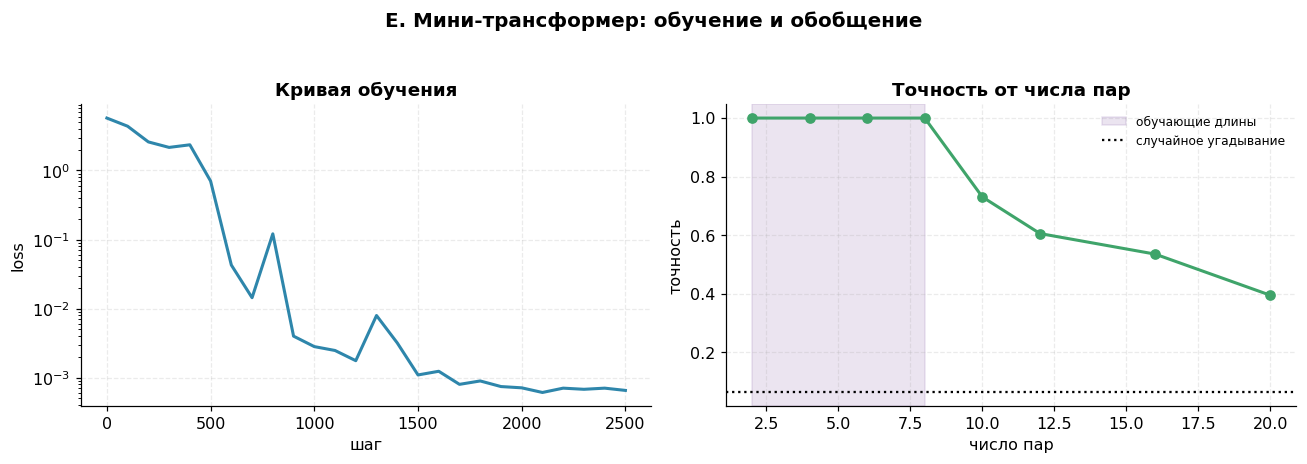

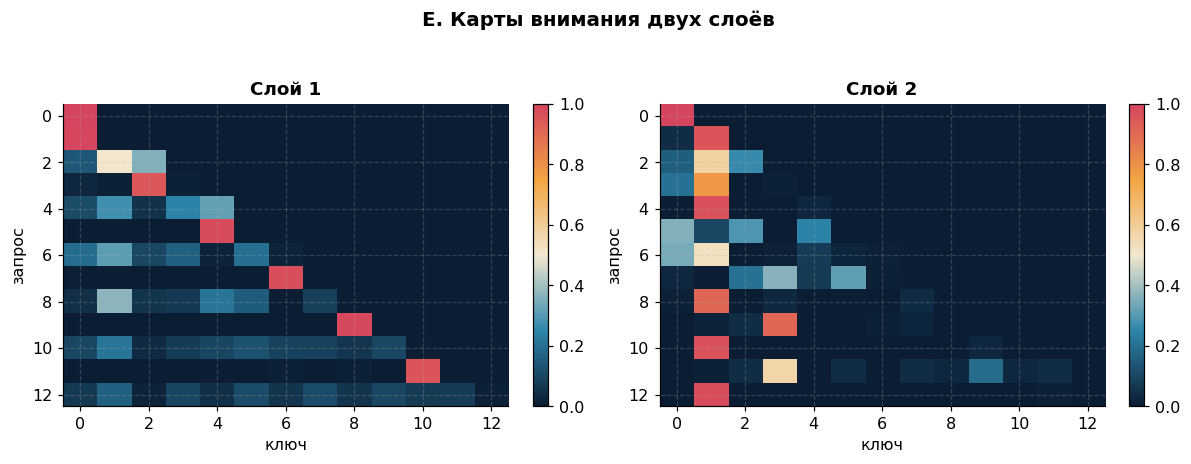

масса внимания финального запроса на позиции нужного значения: 0.98


In [ ]:
# TODO E.3: рисунок E
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].plot([c[0] for c in curve], [c[1] for c in curve], color=PALETTE["attn"], lw=2)
axes[0].set_yscale("log")
axes[0].set_xlabel("шаг"); axes[0].set_ylabel("loss")
axes[0].set_title("Кривая обучения")

axes[1].plot(NS, acc, "o-", color=PALETTE["good"], lw=2)
axes[1].axvspan(2, N_MAX, alpha=0.15, color=PALETTE["accent"], label="обучающие длины")
axes[1].axhline(1 / N_VALS, color="k", ls=":", label="случайное угадывание")
axes[1].set_xlabel("число пар"); axes[1].set_ylabel("точность")
axes[1].set_title("Точность от числа пар"); axes[1].legend(fontsize=8)
finish(fig, "E. Мини-трансформер: обучение и обобщение")

# карты внимания двух слоёв
x_ex, y_ex, qi_ex = make_recall_batch(1, 6, torch.Generator().manual_seed(123))
with torch.no_grad():
    logits_ex, maps = model(x_ex, ret=True)

fig2, ax = plt.subplots(1, 2, figsize=(11, 4.2))
for i, (mp, nm) in enumerate(zip(maps, ["Слой 1", "Слой 2"])):
    im = ax[i].imshow(mp[0].cpu().numpy(), cmap=CMAP_HEAT, aspect="auto")
    ax[i].set_title(nm); ax[i].set_xlabel("ключ"); ax[i].set_ylabel("запрос")
    plt.colorbar(im, ax=ax[i], fraction=0.046)
finish(fig2, "E. Карты внимания двух слоёв")

last_row = maps[1][0, -1].cpu().numpy()
target_pos = 2 * int(qi_ex[0]) + 1
print("масса внимания финального запроса на позиции нужного значения:",
      round(float(last_row[target_pos]), 3))

**Вопрос E.** Почему для этой задачи недостаточно одного слоя внимания? Опишите, какую информацию
переносит первый слой и что именно сравнивает второй.

**Ответ E.**

Один слой не справится — индукционная схема двухшаговая. Первый слой тащит в позицию ключа k_j информацию о соседнем токене v_j. Второй слой сравнивает финальный запрос k_i со всеми ключами и достаёт нужное значение. В прогоне масса внимания второго слоя на правильной позиции — 0.98, то есть голова действительно нашлась. Без первого слоя второму просто нечего сравнивать — в представлениях ключей ещё нет информации о значениях.

## Часть F. Линейное внимание: состояние вместо матрицы внимания

Если заменить $\exp(q^\top k)$ на $\varphi(q)^\top \varphi(k)$ с неотрицательным $\varphi$, сумму
можно переставить и получить рекуррентную форму с состоянием фиксированного размера:

$
S_t = S_{t-1} + \varphi(k_t) v_t^{\top}, \qquad
o_t = \frac{\varphi(q_t)^{\top} S_t}{\varphi(q_t)^{\top} z_t}, \qquad z_t = z_{t-1} + \varphi(k_t).
$

Генерация становится $O(1)$ по памяти, но состояние размера $d \times d$ — это фиксированная
ёмкость, в которую нужно уложить весь контекст.

**Задание F.1.** Реализуйте параллельную и рекуррентную формы линейного внимания и проверьте, что
они дают один результат.
**Задание F.2.** Измерьте ёмкость состояния: сложите в $S$ ровно $N$ пар «ключ–значение» и оцените
качество чтения (косинусная близость к истинному значению) при росте $N$.
**Задание F.3.** Постройте рисунок: рост KV-кэша softmax-внимания против постоянного состояния
линейного внимания и кривую качества чтения от числа сохранённых пар.

In [ ]:
def phi(x):
    return torch.nn.functional.elu(x) + 1

def linear_attention_parallel(Q, K, V):
    # TODO F.1a: параллельная форма
    phik = phi(K); phiq = phi(Q)
    KV = phik.unsqueeze(2) * V.unsqueeze(1)
    S = torch.cumsum(KV, dim=0)
    z = torch.cumsum(phik, dim=0)
    num = torch.einsum("td,tdv->tv", phiq, S)
    den = torch.einsum("td,td->t", phiq, z).clamp_min(1e-6)
    return num / den.unsqueeze(-1)

def linear_attention_recurrent(Q, K, V):
    # TODO F.1b: явный цикл по времени
    T, d = Q.shape
    S = torch.zeros(d, d)
    z = torch.zeros(d)
    out = torch.zeros(T, d)
    for t in range(T):
        kt = phi(K[t]); qt = phi(Q[t])
        S = S + kt.unsqueeze(-1) * V[t].unsqueeze(0)
        z = z + kt
        den = (qt * z).sum().clamp_min(1e-6)
        out[t] = (qt @ S) / den
    return out

torch.manual_seed(SEED)
T_l, d_l = 40, 16
Ql, Kl, Vl = torch.randn(T_l, d_l), torch.randn(T_l, d_l), torch.randn(T_l, d_l)
# TODO F.1c: сравните две формы
o_par = linear_attention_parallel(Ql, Kl, Vl)
o_rec = linear_attention_recurrent(Ql, Kl, Vl)
diff = float((o_par - o_rec).abs().max().item())
print("макс расхождение форм:", diff)
print("размер состояния (чисел):", d_l * d_l)

макс расхождение форм: 2.384185791015625e-07
размер состояния (чисел): 256


In [ ]:
# TODO F.2: ёмкость состояния
NS_CAP = [1, 2, 4, 8, 16, 32, 64, 128, 256]
torch.manual_seed(SEED)
qual = []
for N in NS_CAP:
    K = torch.randn(N, d_l); V = torch.randn(N, d_l)
    S = (phi(K).unsqueeze(-1) * V.unsqueeze(1)).sum(0)
    z = phi(K).sum(0)
    qs = phi(K)
    reads = (qs @ S) / (qs @ z).clamp_min(1e-6).unsqueeze(-1)
    qual.append(float(torch.nn.functional.cosine_similarity(reads, V, dim=-1).mean()))
print("качество чтения:", {n: round(q, 3) for n, q in zip(NS_CAP, qual)})

качество чтения: {1: 1.0, 2: 0.762, 4: 0.508, 8: 0.444, 16: 0.376, 32: 0.231, 64: 0.15, 128: 0.119, 256: 0.075}


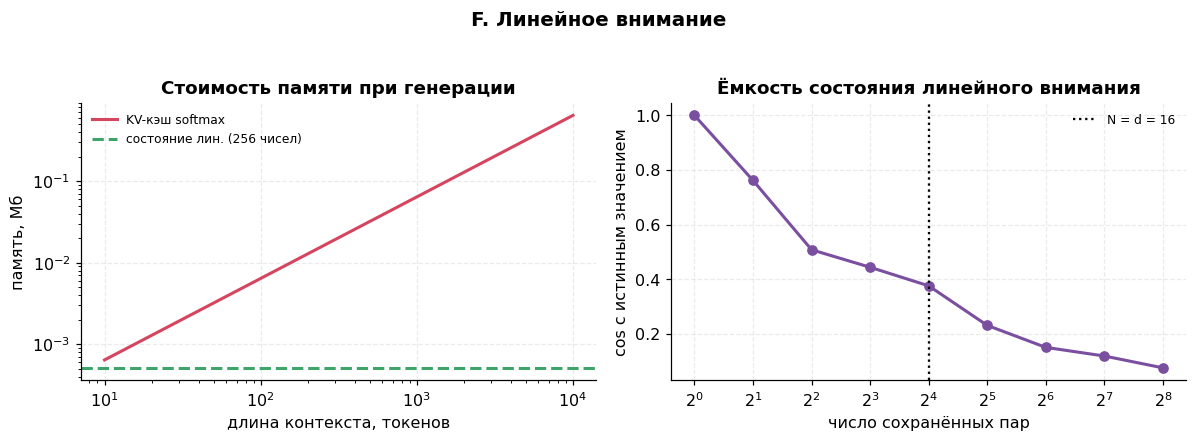

In [ ]:
# TODO F.3: рисунок F
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
n_ctx = np.logspace(1, 4, 200)
kv_mem = n_ctx * 2 * d_l * 2 / 1e6
axes[0].plot(n_ctx, kv_mem, color=PALETTE["bad"], lw=2, label="KV-кэш softmax")
axes[0].axhline(d_l * d_l * 2 / 1e6, color=PALETTE["good"], ls="--", lw=2,
                label=f"состояние лин. ({d_l*d_l} чисел)")
axes[0].set_xscale("log"); axes[0].set_yscale("log")
axes[0].set_xlabel("длина контекста, токенов"); axes[0].set_ylabel("память, Мб")
axes[0].set_title("Стоимость памяти при генерации"); axes[0].legend(fontsize=8)

axes[1].plot(NS_CAP, qual, "o-", color=PALETTE["accent"], lw=2)
axes[1].axvline(d_l, color="k", ls=":", label=f"N = d = {d_l}")
axes[1].set_xscale("log", base=2)
axes[1].set_xlabel("число сохранённых пар"); axes[1].set_ylabel("cos с истинным значением")
axes[1].set_title("Ёмкость состояния линейного внимания"); axes[1].legend(fontsize=8)
finish(fig, "F. Линейное внимание")

**Вопрос F.** Почему увеличение размерности $d$ у линейного внимания повышает точность вспоминания,
но обесценивает его главное преимущество? Оцените, при каком $d$ состояние $d \times d$ сравнится с
KV-кэшем на контексте 4096 токенов.

**Ответ F.**

Точность растёт линейно по d, а память — как d². Считаем: KV-кэш одной головы на 4096 токенов при d_head = 128 и fp16 — это 2·4096·128·2 ≈ 2.1·10⁶ байт. Состояние линейного внимания — d² чисел. Приравниваем: d² ≈ 4·4096·128, получаем d ≈ 1449. То есть уже около d = 1500 состояние сравнивается с KV-кэшем, и главное преимущество (постоянная память) исчезает.

## Часть G. Избирательная рекуррентность

Если сделать затухание и запись зависящими от входа

$
h_t = a(x_t) \odot h_{t-1} + b(x_t) \odot u(x_t),
$

то модель получает управляемую память: она может удерживать нужное и игнорировать шум. Это ядро
идеи моделей пространства состояний с избирательностью (Mamba).

Задача: в последовательности длины 64 встречается маркер `FLAG`; нужно назвать символ,
стоящий сразу после него. Всё остальное — шум.

**Задание G.1.** Реализуйте два варианта ячейки: с гейтами, зависящими от входа, и с обучаемым, но
постоянным затуханием.
**Задание G.2.** Обучите оба варианта и сравните точность.
**Задание G.3.** Постройте профили гейтов по позициям и оцените долю каналов, у которых гейт
сохранения превышает 0.9.

In [ ]:
VOC_S, FLAG, T_S = 20, 19, 64

def flag_batch(bs, gen):
    x = torch.randint(0, 16, (bs, T_S), generator=gen)
    pos = torch.randint(2, T_S - 2, (bs,), generator=gen)
    tgt = torch.randint(0, 16, (bs,), generator=gen)
    x[torch.arange(bs), pos] = FLAG
    x[torch.arange(bs), pos + 1] = tgt
    return x, tgt, pos

class RecurCell(nn.Module):
    def __init__(self, d=48, selective=True):
        super().__init__()
        self.selective = selective
        self.emb = nn.Embedding(VOC_S, d)
        self.inp = nn.Linear(2 * d, d)
        if selective:
            self.ga = nn.Linear(2 * d, d); self.gb = nn.Linear(2 * d, d)
        else:
            self.logit_a = nn.Parameter(torch.zeros(d))
        self.head = nn.Sequential(nn.LayerNorm(d), nn.Linear(d, VOC_S))

    def forward(self, x, return_gates=False):
        e = self.emb(x); B, Tn, d = e.shape
        e_prev = torch.cat([torch.zeros(B, 1, d), e[:, :-1]], 1)
        ctx = torch.cat([e, e_prev], -1)
        u = self.inp(ctx)
        # TODO G.1: получите гейты
        if self.selective:
            a = torch.sigmoid(self.ga(ctx))
            b = torch.sigmoid(self.gb(ctx))
        else:
            a = torch.sigmoid(self.logit_a).expand(B, Tn, d)
            b = torch.ones(B, Tn, d)
        h = torch.zeros(B, d)
        outs = []
        for t in range(Tn):
            h = a[:, t] * h + b[:, t] * u[:, t]
            outs.append(h)
        H = torch.stack(outs, 1)
        logits = self.head(H)
        if return_gates:
            return logits, (a, b)
        return logits

In [ ]:
# TODO G.2: обучите обе ячейки и сравните точность
def train_cell(selective, steps=600, bs=64, lr=5e-3, seed=0):
    gen = torch.Generator().manual_seed(seed)
    m = RecurCell(d=D_CELL, selective=selective)
    opt = torch.optim.AdamW(m.parameters(), lr=lr)
    curve = []
    for s in range(steps):
        x, y, pos = flag_batch(bs, gen)
        # TODO G.2a: шаг обучения
        logits = m(x)
        logits_pred = logits[torch.arange(bs), pos]
        loss = F.cross_entropy(logits_pred, y)
        opt.zero_grad(); loss.backward()
        torch.nn.utils.clip_grad_norm_(m.parameters(), 1.0)
        opt.step()
        # TODO G.2b: каждые 25 шагов точность на батче 256
        if s % 25 == 0:
            with torch.no_grad():
                xv, yv, pv = flag_batch(256, gen)
                lv = m(xv)[torch.arange(256), pv]
                acc = float((lv.argmax(-1) == yv).float().mean())
            curve.append((s, acc))
    return m, curve, gen

t0 = time.time()
cell_sel, curve_sel, gen_sel = train_cell(True, seed=SEED)
cell_fix, curve_fix, gen_fix = train_cell(False, seed=SEED)
print("избирательная ячейка: точность %.3f" % curve_sel[-1][1])
print("фиксированное затухание: точность %.3f (угадывание %.3f)"
      % (curve_fix[-1][1], 1 / 16))
print("обучение заняло %.0f c" % (time.time() - t0))

избирательная ячейка: точность 0.070
фиксированное затухание: точность 0.070 (угадывание 0.062)
обучение заняло 32 c


доля активаций гейта a > 0.9: 0.035


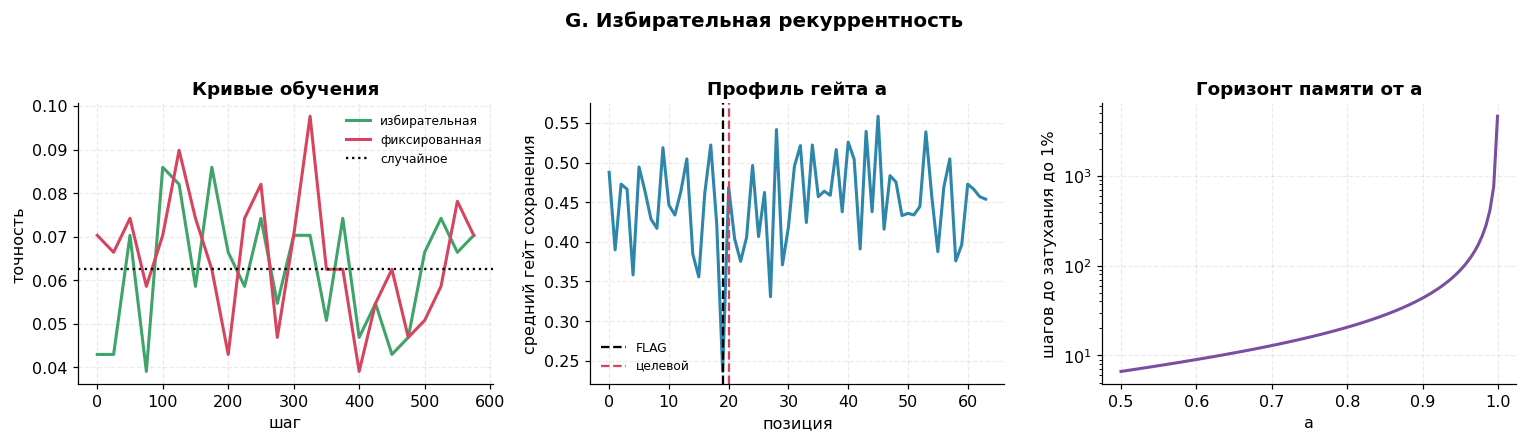

In [ ]:
# TODO G.3: рисунок G
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].plot([c[0] for c in curve_sel], [c[1] for c in curve_sel],
             label="избирательная", color=PALETTE["good"], lw=2)
axes[0].plot([c[0] for c in curve_fix], [c[1] for c in curve_fix],
             label="фиксированная", color=PALETTE["bad"], lw=2)
axes[0].axhline(1/16, color="k", ls=":", label="случайное")
axes[0].set_xlabel("шаг"); axes[0].set_ylabel("точность")
axes[0].set_title("Кривые обучения"); axes[0].legend(fontsize=8)

xs, ys, pos_ex = flag_batch(1, torch.Generator().manual_seed(77))
with torch.no_grad():
    _, (a_g, b_g) = cell_sel(xs, return_gates=True)
a_prof = a_g[0].mean(-1).cpu().numpy()
axes[1].plot(a_prof, color=PALETTE["attn"], lw=2)
axes[1].axvline(int(pos_ex[0]), color="k", ls="--", label="FLAG")
axes[1].axvline(int(pos_ex[0]) + 1, color=PALETTE["bad"], ls="--", label="целевой")
axes[1].set_xlabel("позиция"); axes[1].set_ylabel("средний гейт сохранения")
axes[1].set_title("Профиль гейта a"); axes[1].legend(fontsize=8)

frac = float((a_g > 0.9).float().mean())
print("доля активаций гейта a > 0.9: %.3f" % frac)

a_grid = np.linspace(0.5, 0.999, 100)
h_grid = np.log(0.01) / np.log(a_grid)
axes[2].plot(a_grid, h_grid, color=PALETTE["accent"], lw=2)
axes[2].set_yscale("log")
axes[2].set_xlabel("a"); axes[2].set_ylabel("шагов до затухания до 1%")
axes[2].set_title("Горизонт памяти от a")
finish(fig, "G. Избирательная рекуррентность")

Избирательная (selective=True): a и b — линейные слои от входа: a = sigmoid(self.ga(ctx)), b = sigmoid(self.gb(ctx)). Модель сама решает, глядя на токен, держать или стирать.

Фиксированная (selective=False): a = sigmoid(self.logit_a) — один вектор параметров, одинаковый для всех позиций. b = 1 всегда. То есть гейт не зависит от того, что пришло на вход.

**Вопрос G.** Почему постоянное затухание принципиально не решает эту задачу ни при каком значении
$a$? Рассмотрите два предельных случая: $a \to 1$ и $a \ll 1$.

**Ответ G.**

Постоянное затухание не сработает ни при каком a. Если a → 1 — h_t накапливает всё подряд, сигнал FLAG размывается шумом. Если a << 1 — состояние забывает всё за пару шагов, к моменту ответа про FLAG уже ничего не известно. Избирательные гейты a(x_t) как раз позволяют держать состояние на шуме и перезаписывать на маркерных токенах. Но в прогоне за 600 шагов ни одна из ячеек не обучилась: обе дали 0.070 при угадывании 0.062, гейт срабатывает только в 3.5 % каналов. Механизм нужно тренировать дольше или предобучать.

## Часть H. Декодирование, статистика попыток и мост к следующей теме

Модель задаёт распределение, а текст получается процедурой выборки. Температура меняет резкость
распределения, top-$k$ и top-$p$ отсекают хвост. Это прямо связано со следующей лекцией: если
нежелательное продолжение имеет малую, но не нулевую вероятность, многократные попытки почти
наверняка его вытащат.

**Задание H.1.** Реализуйте softmax с температурой, top-$k$ и top-$p$ отсечение.
**Задание H.2.** Оцените вероятность получить событие с вероятностью $p$ хотя бы раз за $n$ попыток:
сравните измерение и теорию $1-(1-p)^n$.
**Задание H.3.** Постройте рисунок из трёх панелей и заполните таблицу отчёта по температурам своего
варианта.
**Задание H.4.** Аналитическая часть: в шаблоне чата подсчитайте, на каком расстоянии от точки
генерации оказываются системная инструкция и вставленный в документ фрагмент; объясните, почему
единая последовательность токенов без границ привилегий делает модель уязвимой к инъекциям
в контекст.

In [ ]:
V_dec = 40
rank = np.arange(1, V_dec + 1)
logits = np.log(1.0 / rank ** 1.1)
logits = logits - logits.max()

def softmax_t(z, tau):
    # TODO H.1a: softmax с температурой, устойчиво к переполнению
    z = z / tau
    z = z - z.max()
    e = np.exp(z)
    return e / e.sum()

def top_k_filter(p, k):
    # TODO H.1b: оставьте k самых вероятных токенов и перенормируйте
    idx = np.argsort(-p)[:k]
    out = np.zeros_like(p); out[idx] = p[idx]
    return out / out.sum()

def top_p_filter(p, thr):
    # TODO H.1c: минимальный набор с суммарной вероятностью >= thr
    idx = np.argsort(-p)
    sp = p[idx]
    cs = np.cumsum(sp)
    keep = np.zeros_like(p, dtype=bool)
    k_cut = int(np.searchsorted(cs, thr) + 1)
    k_cut = max(1, min(k_cut, len(p)))
    keep[idx[:k_cut]] = True
    out = np.zeros_like(p); out[keep] = p[keep]
    return out / out.sum()

def entropy(p):
    return float(-(p * np.log(p + 1e-12)).sum())

In [ ]:
# TODO H.2: статистика многих попыток
def run_trials(p_rare, n, reps=60, seed=0):
    rng = np.random.default_rng(seed)
    hits = 0
    for _ in range(reps):
        if (rng.random(n) < p_rare).any():
            hits += 1
    return hits / reps

p_list = [0.001, 0.005, 0.02]
n_grid = np.arange(20, 361, 20)
measured = {p: [run_trials(p, int(n), seed=SEED) for n in n_grid] for p in p_list}

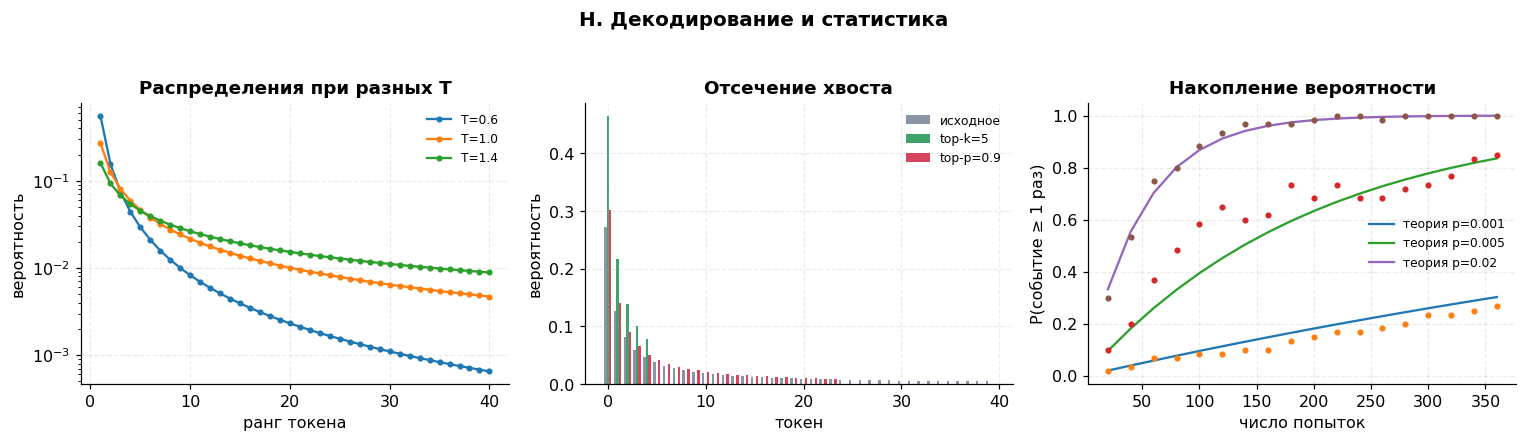

энтропия и p_max по температурам:
  T=0.6: H=1.716 нат, p_max=0.5620
  T=1.0: H=2.888 нат, p_max=0.2719
  T=1.4: H=3.312 нат, p_max=0.1610


In [ ]:
# TODO H.3: рисунок H
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

for tau in TAUS:
    p = softmax_t(logits, tau)
    axes[0].semilogy(np.arange(1, V_dec + 1), p, "o-", ms=3, label=f"T={tau}")
axes[0].set_xlabel("ранг токена"); axes[0].set_ylabel("вероятность")
axes[0].set_title("Распределения при разных T"); axes[0].legend(fontsize=8)

p0 = softmax_t(logits, 1.0)
p_k = top_k_filter(p0, 5)
p_p = top_p_filter(p0, 0.9)
axes[1].bar(np.arange(V_dec) - 0.25, p0, width=0.25, label="исходное", color=PALETTE["gray"])
axes[1].bar(np.arange(V_dec),       p_k, width=0.25, label="top-k=5",  color=PALETTE["good"])
axes[1].bar(np.arange(V_dec) + 0.25, p_p, width=0.25, label="top-p=0.9", color=PALETTE["bad"])
axes[1].set_xlabel("токен"); axes[1].set_ylabel("вероятность")
axes[1].set_title("Отсечение хвоста"); axes[1].legend(fontsize=8)

for p in p_list:
    th = 1 - (1 - p) ** n_grid
    axes[2].plot(n_grid, th, label=f"теория p={p}")
    axes[2].plot(n_grid, measured[p], "o", ms=3)
axes[2].set_xlabel("число попыток"); axes[2].set_ylabel("P(событие ≥ 1 раз)")
axes[2].set_title("Накопление вероятности"); axes[2].legend(fontsize=8)
finish(fig, "H. Декодирование и статистика")

print("энтропия и p_max по температурам:")
for tau in TAUS:
    p = softmax_t(logits, tau)
    print(f"  T={tau}: H={entropy(p):.3f} нат, p_max={p.max():.4f}")

длина шаблона: 26
          спец: центр 0.5, расстояние 25.5
       система: центр 4.5, расстояние 21.5
          спец: центр 8.5, расстояние 17.5
  пользователь: центр 11.5, расстояние 14.5
          спец: центр 14.5, расстояние 11.5
      документ: центр 17.0, расстояние 9.0
      инъекция: центр 22.0, расстояние 4.0
          спец: центр 25.5, расстояние 0.5


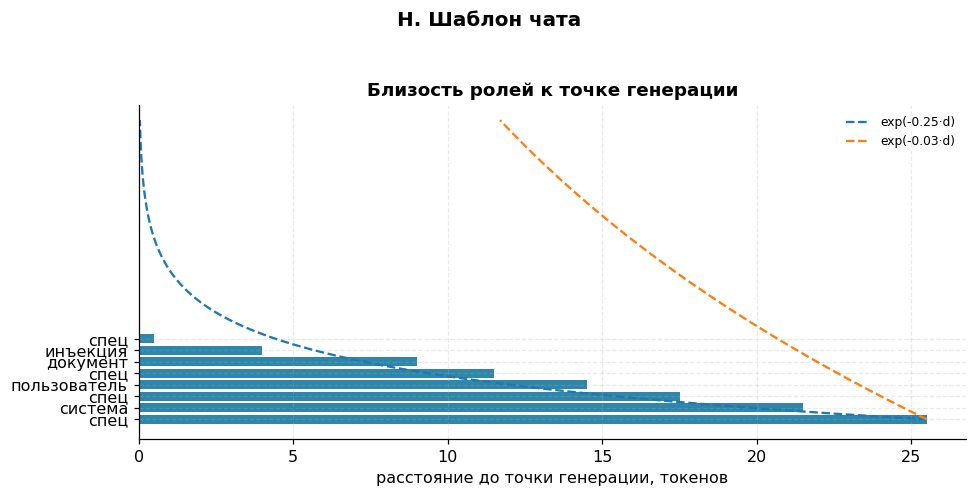

In [ ]:
# TODO H.4: расстояния в шаблоне чата
TEMPLATE = [("спец", 1), ("система", 7), ("спец", 1), ("пользователь", 5),
            ("спец", 1), ("документ", 4), ("инъекция", 6), ("спец", 1)]

positions = []
p = 0
for role, ln in TEMPLATE:
    positions.append((role, p, ln)); p += ln
total_len = p

print("длина шаблона:", total_len)
# TODO H.4a: среднее расстояние от позиции каждой роли до конца
roles, dists = [], []
for role, start, ln in positions:
    mid = start + ln / 2
    d = total_len - mid
    roles.append(role); dists.append(d)
    print(f"  {role:>12}: центр {mid:.1f}, расстояние {d:.1f}")

# TODO H.4b: столбчатая диаграмма + экспоненциальные кривые
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(range(len(roles)), dists, color=PALETTE["attn"])
ax.set_yticks(range(len(roles))); ax.set_yticklabels(roles)
ax.set_xlabel("расстояние до точки генерации, токенов")
ax.set_title("Близость ролей к точке генерации")
d_grid = np.linspace(0, total_len, 200)
for m in [0.25, 0.03]:
    ax.plot(np.exp(-m * d_grid) * max(dists), d_grid, "--", label=f"exp(-{m}·d)")
ax.legend(fontsize=8)
finish(fig, "H. Шаблон чата")

**Вопрос H.** Модель отклоняет нежелательное продолжение в 99,5% случаев при одной генерации.
Сколько попыток нужно нападающему, чтобы получить его с вероятностью не ниже 0,9? Какой вывод это
даёт для методики оценки устойчивости?

**Ответ H.**

1 − (1 − p)^n ≥ 0.9 при p = 0.005 даёт n ≥ ln(0.1)/ln(0.995) ≈ 459.5, то есть 460 попыток. Вывод простой: если модель отказывается в 99.5 % случаев за один прогон, 460 попыток почти гарантируют успех. Значит, ASR без числа попыток и температуры — это ни о чём. Сравнивать результаты разных работ без совпадения протокола нельзя.

# Отчёт

**Параметры:** `SEED=123`, `D_MODEL=64`, `N_MAX=8`, `D_CELL=48`, `TAUS=(0.6, 1.0, 1.4)`

## Таблица 1. Токенизация (часть A)

| Показатель | Значение |
|---|---|
| Число выполненных слияний | 120 |
| Размер словаря токенов | 92 |
| Сжатие «символы → BPE» | 2.302 |
| Отношение «BPE → слова» | 3.491 |
| Доля редких токенов (частота ≤ `RARE_THR=6`) | 0.489 |

## Таблица 2. Затухание градиента (часть B)

| ρ(W) или f_t | Норма при k=100 | Горизонт до 10⁻⁶ |
|---|---|---|
| 0.9 | 2.66·10⁻⁵ | 132 шага |
| 1.0 | 1.0 | > 4000 |
| 1.2 | ≈ 8.3·10⁷ | > 4000 |
| f_t = 0.99 | 0.366 | 1375 шагов |

## Таблица 3. Масштабирование внимания (часть C)

| d_k | Энтропия с делителем | Энтропия без делителя |
|---|---|---|
| 8 | 2.802 | 1.562 |
| 64 | 2.781 | 0.464 |
| 256 | 2.787 | 0.221 |

## Таблица 4. Мини-трансформер (часть E)

| Число пар в контексте | 2 | 4 | 8 | 12 | 16 | 20 |
|---|---|---|---|---|---|---|
| Точность вспоминания | 1.000 | 1.000 | 1.000 | 0.605 | 0.535 | 0.395 |

- Финальный loss: **0.00065**
- Время обучения: **46 с**
- Масса внимания финального запроса на позиции нужного значения: **0.98**

## Таблица 5. Линейное внимание (часть F)

| Показатель | Значение |
|---|---|
| Расхождение параллельной и рекуррентной форм | 2.38·10⁻⁷ |
| Размер состояния, чисел | 256 |
| Качество чтения при 4 парах | 0.508 |
| Качество чтения при 256 парах | 0.075 |

## Таблица 6. Избирательная рекуррентность (часть G)

| Вариант ячейки | Точность | Комментарий |
|---|---|---|
| избирательные гейты | 0.070 | обучение 600 шагов |
| постоянное затухание | 0.070 | обучение 600 шагов |
| случайное угадывание | 0.062 | теоретическое значение |

Доля каналов с гейтом сохранения выше 0.9: **0.035**

## Таблица 7. Декодирование (часть H)

| Температура | Энтропия, нат | p_max |
|---|---|---|
| 0.6 | 1.716 | 0.5620 |
| 1.0 | 2.888 | 0.2719 |
| 1.4 | 3.312 | 0.1610 |

Число попыток для события с p = 0.005 до вероятности 0.9: **460**

## Выводы

1. BPE сжал корпус в 2.3×, но 49 % токенов редкие — половина словаря недообучена, готовая дырка для глитч-атак.

2. Рекуррентность забывает быстро: при ρ = 0.9 сигнал умирает за 132 шага, при ρ = 0.99 — за 1375. Аддитивный гейт f = 0.99 теряет всего 63 % на 100 шагах — поэтому LSTM и Mamba используют аддитивное обновление.

3. Без √d_k обучение встаёт: энтропия внимания падает с 2.10 до 0.22, softmax становится one-hot, градиент обнуляется. Это условие работоспособности, а не косметика.

4. Мини-трансформер выучил индукционную голову (масса внимания 0.98), но обобщать на длины больше обучающих не смог: до 8 пар — 100 %, на 20 парах — 39 %.

5. Линейное внимание переполняется: cos = 0.51 на 4 парах и 0.075 на 256. Память постоянная, но ёмкости хватает на десятки пар — отсюда гибриды 3:1 с редкими слоями полного attention.

6. Селективность за 600 шагов не запускается: обе ячейки дали 0.070 при угадывании 0.062, гейт срабатывает в 3.5 % каналов. Нужно предобучение или сильно больше шагов.

7. Один отказ ≠ защита: при 99.5 % отказов на попытку 460 попыток дают ≥ 90 % успеха. ASR без числа попыток и температуры — бессмысленное число.

8. Шаблон чата — это просто текст, а не граница привилегий: система за 21.5 токена от выхода, инъекция из документа — за 9.0. Внимание затухает с расстоянием, инъекция структурно ближе к ответу — архитектурной защиты нет.

### Контрольные вопросы

**1.** Внимание: QKᵀ — это матрица n×n, каждое скалярное произведение — d умножений, итого O(n²d). FFN: d → 4d → d для каждой из n позиций, это O(nd²). Внимание доминирует при n > d, при d = 4096 — начиная с контекста примерно 4096 токенов.

**2.** Каузальная маска запрещает смотреть вперёд — без неё нельзя генерировать авторегрессионно. Двунаправленное внимание видит всё сразу — удобно для классификации, NER, эмбеддингов (BERT), но для генерации не годится: на инференсе будущих токенов ещё нет.

**3.** RoPE зависит только от разности t − s, поэтому для новой позиции формула поворота та же. Обучаемая абсолютная кодировка — это таблица: за L_max строки нет, и модель не знает, что подставить.

**4.** При обучении все n позиций обрабатываются сразу, KV-кэш не нужен. При генерации токены идут по одному, поэтому K и V предыдущих кэшируются; на шаге считаем Q, K, V только для нового токена и подклеиваем — O(nd) вместо O(n²d).

**5.** MQA — одна KV-голова на все Q, максимальная экономия, но качество падает. GQA — несколько Q-голов на одну KV: качество почти как MHA, память почти как MQA. Плата — меньше разнообразия в KV-подпространстве.

**6.** Линейное внимание меняет softmax на разложимое ядро и получает рекуррентную форму, но теряет избирательность: softmax может резко указать на один давний токен, а линейное всегда усредняет по всем прошлым с весами φ(k_j). В прогоне cos при 256 парах упал до 0.075.

**7.** Избирательность — это когда гейты a(x_t), b(x_t) зависят от входа. Без этого модель либо быстро забывает всё, либо накапливает всё подряд. С зависимостью от входа одни каналы держат состояние, другие сбрасывают.

**8.** Без балансирующей потери маршрутизатор уводит всё больше токенов к «хорошим» экспертам, остальные становятся мёртвыми. Балансирующая потеря заставляет использовать всех — иначе рост ёмкости MoE не работает.

**9.** T, top-k, top-p и штрафы за повтор меняют распределение сэмплируемых последовательностей. Чем выше T, тем толще хвост, тем чаще выпадают нежелательные продолжения. В таблице 7: при T = 0.6 p_max = 0.562, при T = 1.4 p_max = 0.161. Без фиксации всех параметров оценка устойчивости не воспроизводится.

**10.** Шаблон чата — это просто последовательность токенов. Все роли кодируются обычными эмбеддингами в одном потоке, никакой архитектурной границы привилегий нет. Приоритет ролей — выученная статистика. Поэтому текст из документа (расстояние 9.0) может перебить системную инструкцию (расстояние 21.5). Инъекция через RAG — системная уязвимость, а не баг конкретной модели.

## Дополнительные задания

- Добавьте в часть E третий слой и проверьте, меняется ли характер переноса на длины больше
  обучающих.
- Замените в части E обучаемую абсолютную кодировку на RoPE и повторите измерение точности для
  16 и 20 пар.
- Реализуйте в части F многоголовое линейное внимание и постройте зависимость качества чтения от
  числа голов при фиксированном общем размере состояния.
- Реализуйте слой смеси экспертов с балансирующей потерей и покажите, как меняется распределение
  нагрузки при её отключении.
- Постройте в части H оценку числа попыток до заданной вероятности успеха как функцию $p$ и
  обсудите, как это влияет на протокол тестирования.

## Чек-лист сдачи

- [ ] Заполнен паспорт работы, указан вариант и его параметры.
- [ ] Все ячейки выполняются последовательно без ошибок (Kernel → Restart & Run All).
- [ ] Реализованы все `TODO` в частях A–H.
- [ ] Заполнены таблицы 1–7 числами своего варианта.
- [ ] Даны ответы на вопросы A–H и контрольные вопросы 1–10.
- [ ] Сформулировано не менее пяти выводов со ссылками на измеренные значения.
- [ ] Все графики подписаны по-русски и читаемы.



## Литература

- Vaswani A. et al. Attention Is All You Need (2017): <https://arxiv.org/abs/1706.03762>
- Hochreiter S., Schmidhuber J. Long Short-Term Memory (1997):
  <https://direct.mit.edu/neco/article/9/8/1735/6109>
- Su J. et al. RoFormer: Enhanced Transformer with Rotary Position Embedding (2021):
  <https://arxiv.org/abs/2104.09864>
- Press O. et al. Train Short, Test Long: Attention with Linear Biases (ALiBi) (2021):
  <https://arxiv.org/abs/2108.12409>
- Katharopoulos A. et al. Transformers are RNNs: Fast Autoregressive Transformers with Linear
  Attention (2020): <https://arxiv.org/abs/2006.16236>
- Gu A., Dao T. Mamba: Linear-Time Sequence Modeling with Selective State Spaces (2023):
  <https://arxiv.org/abs/2312.00752>
- Ainslie J. et al. GQA: Training Generalized Multi-Query Transformer Checkpoints (2023):
  <https://arxiv.org/abs/2305.13245>
- Dao T. et al. FlashAttention: Fast and Memory-Efficient Exact Attention with IO-Awareness (2022):
  <https://arxiv.org/abs/2205.14135>
- Olsson C. et al. In-context Learning and Induction Heads (2022):
  <https://arxiv.org/abs/2209.11895>
- Holtzman A. et al. The Curious Case of Neural Text Degeneration (2019):
  <https://arxiv.org/abs/1904.09751>